# Chapter 21: Scaling to a million users

Companion notebook for [ch21/README.md](../README.md). Run it top to bottom from this directory
(`uv run jupyter nbconvert --to notebook --execute --inplace ch21.ipynb`); every number in the
chapter comes from the saved outputs below.

What it needs: the ShopFlow Postgres on :5433, Docker (it starts a `redis:8-alpine` container named
`ch21-redis` on :6386), free ports 8021/8121/8221, `.env` for the few real-model calls, and Ollama
for the local fallback. The load tests themselves never call a real model: they hit
`mock_llm_server.py`, calibrated against `openai/gpt-6-luna` in section 2. Runtime: about 20 minutes.

In [1]:
import asyncio
import json
import os
import random
import subprocess
import sys
import threading
import time
import uuid
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
from pathlib import Path
from statistics import median

import matplotlib.pyplot as plt
import openai
import pandas as pd
import redis
import redis.asyncio as aredis

CODE = Path.cwd()
sys.path.insert(0, str(CODE))
IMAGES = CODE.parent / "images"
IMAGES.mkdir(exist_ok=True)

import ch21_jobqueue as q
import ch21_loadtest as lt
from ch21_napkin import Price, Workload, daily_cost, peak_to_avg_from_hourly, plan, servers_needed
from ch21_ratelimit import AsyncRedisTokenBucket, RedisTokenBucket, TokenBucket
from ch21_resilience import (AllProvidersFailed, CircuitBreaker, Provider, complete_with_failover, exponential_delay,
                             full_jitter_delay, retry_async)
from llmprod import chat_client, connect, get_settings
from previous_chapters import SYSTEM_PROMPT, count_tokens

settings = get_settings()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

REDIS_URL = "redis://localhost:6386/0"
started_redis = False
try:
    redis.Redis.from_url(REDIS_URL).ping()
except redis.exceptions.ConnectionError:
    subprocess.run("docker start ch21-redis || docker run -d --name ch21-redis "
                   "-p 127.0.0.1:6386:6379 redis:8-alpine", shell=True, check=True,
                   capture_output=True)
    started_redis = True
    for _ in range(50):
        try:
            redis.Redis.from_url(REDIS_URL).ping()
            break
        except redis.exceptions.ConnectionError:
            time.sleep(0.2)
r_info = redis.Redis.from_url(REDIS_URL).info("server")
print("redis server", r_info["redis_version"], "| started by notebook:", started_redis)
for pkg in ["openai", "fastapi", "uvicorn", "sse-starlette", "locust", "redis", "psycopg", "anyio"]:
    print(f"{pkg:14s} {version(pkg)}")
print("CPUs:", os.cpu_count())

redis server 8.10.3 | started by notebook: True
openai         3.46.0
fastapi        0.162.0
uvicorn        0.54.0
sse-starlette  3.6.0
locust         2.47.0
redis          8.1.0
psycopg        3.3.8
anyio          4.16.0
CPUs: 16


## 1. Napkin math: 1M monthly users → peak RPS → tokens → dollars → rate limits

Peak-to-average comes from real ShopFlow traffic: orders per hour of day (New York time) over the
whole 180-day history, and orders per weekday.

orders: 30,433  busiest hour: 20:00 ET (7.7% of the day)
peak-hour factor 1.84 x busiest-weekday factor 1.24 = 2.29


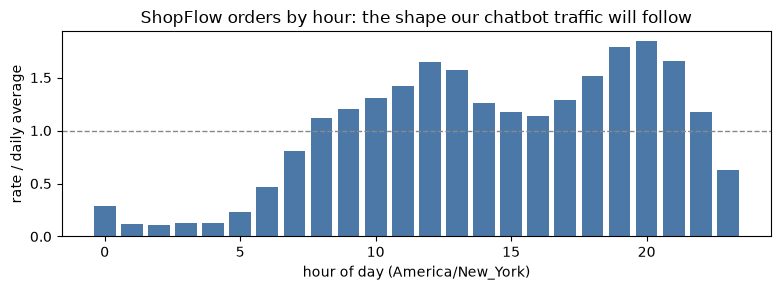

In [2]:
conn = connect()
hourly = dict(conn.execute(
    "SELECT extract(hour FROM placed_at)::int, count(*) FROM orders GROUP BY 1 ORDER BY 1"
).fetchall())
weekday = dict(conn.execute(
    "SELECT extract(isodow FROM placed_at)::int, count(*) FROM orders GROUP BY 1 ORDER BY 1"
).fetchall())
hour_factor = peak_to_avg_from_hourly(hourly)
day_factor = max(weekday.values()) / (sum(weekday.values()) / 7)
print(f"orders: {sum(hourly.values()):,}  busiest hour: {max(hourly, key=hourly.get)}:00 ET "
      f"({max(hourly.values()) / sum(hourly.values()):.1%} of the day)")
print(f"peak-hour factor {hour_factor:.2f} x busiest-weekday factor {day_factor:.2f} "
      f"= {hour_factor * day_factor:.2f}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(list(hourly), [v / sum(hourly.values()) * 24 for v in hourly.values()], color="#4C78A8")
ax.axhline(1, color="#888", ls="--", lw=1)
ax.set_xlabel("hour of day (America/New_York)")
ax.set_ylabel("rate / daily average")
ax.set_title("ShopFlow orders by hour: the shape our chatbot traffic will follow")
fig.tight_layout()
fig.savefig(IMAGES / "21-hourly-profile.png", dpi=150)
plt.show()

## 2. Calibrating the mock against a real model

Five streaming calls to `openai/gpt-6-luna` with Chapter 1's real system prompt (the FAQ). We measure
time to first token (TTFT), decode speed and answer length, and feed them to the mock server.

In [3]:
client = chat_client(timeout=30, max_retries=1)
questions = ["How long do I have to return an item?", "Who pays for return shipping?",
             "Do you ship to Canada?", "How much is express shipping?",
             "My payment failed but I see a charge on my card. What's going on?"]
calib = []
for qn in questions:
    t0 = time.perf_counter()
    ttft, usage = None, None
    stream = client.chat.completions.create(
        model=settings.llm_model, max_tokens=300, reasoning_effort="none", stream=True,
        stream_options={"include_usage": True},
        messages=[{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": qn}])
    for chunk in stream:
        if ttft is None and chunk.choices and chunk.choices[0].delta.content:
            ttft = time.perf_counter() - t0
        if chunk.usage:
            usage = chunk.usage.model_dump()
    total = time.perf_counter() - t0
    calib.append({"question": qn[:40], "ttft_s": round(ttft, 3), "total_s": round(total, 3),
                  "prompt_tokens": usage["prompt_tokens"],
                  "cached": (usage.get("prompt_tokens_details") or {}).get("cached_tokens"),
                  "completion_tokens": usage["completion_tokens"],
                  "decode_tok_s": round((usage["completion_tokens"] - 1) / (total - ttft), 1),
                  "cost_usd": usage.get("cost")})
calib_df = pd.DataFrame(calib)
print(calib_df.to_string(index=False))
spend = {"calibration": float(calib_df.cost_usd.sum())}
MOCK = {"ttft_ms": round(1000 * median(calib_df.ttft_s)),
        "tokens_per_s": round(median(calib_df.decode_tok_s)),
        "output_tokens": round(calib_df.completion_tokens.mean())}
LATENCY_S = median(calib_df.total_s)
print("\nmock config:", MOCK, f"| median total latency {LATENCY_S:.2f}s",
      f"| cost {spend['calibration']:.6f} USD")

                                question  ttft_s  total_s  prompt_tokens  cached  completion_tokens  decode_tok_s  cost_usd
   How long do I have to return an item?   2.604    2.850           1160       0                 26         101.4  0.000158
           Who pays for return shipping?   1.446    1.735           1156    1143                 26          86.5  0.000026
                  Do you ship to Canada?   1.037    1.296           1156    1143                 22          81.2  0.000024
           How much is express shipping?   1.333    1.553           1156    1143                 12          49.8  0.000019
My payment failed but I see a charge on    0.913    1.402           1166    1143                 61         122.6  0.000045

mock config: {'ttft_ms': 1333, 'tokens_per_s': 86, 'output_tokens': 29} | median total latency 1.55s | cost 0.000272 USD


In [4]:
system_tokens = count_tokens([{"role": "system", "content": SYSTEM_PROMPT}])
w = Workload(mau=1_000_000, dau_ratio=0.20, sessions_per_dau=1.5, turns_per_session=4,
             system_tokens=system_tokens, user_tokens=20, output_tokens=MOCK["output_tokens"],
             peak_to_avg=hour_factor * day_factor)
p = plan(w, latency_s=LATENCY_S)
burst = 2.0  # assumption: minute-level spikes on top of the busiest hour (promotions, outages elsewhere)
print(f"assumptions: {w}")
print(f"system prompt: {system_tokens} tokens (tiktoken o200k_base)\n")
rows = [("daily active users", p["dau"]), ("chats / day", p["sessions_per_day"]),
        ("messages (LLM calls) / day", p["messages_per_day"]),
        ("input tokens / day", p["input_tokens_per_day"]),
        ("output tokens / day", p["output_tokens_per_day"]), ("average RPS", p["avg_rps"]),
        ("busiest-hour RPS", p["peak_rps"]), ("design RPS (x2 burst)", p["peak_rps"] * burst),
        ("design RPM", p["peak_rpm"] * burst),
        ("design input TPM", p["peak_input_tpm"] * burst),
        ("design output TPM", p["peak_output_tpm"] * burst),
        ("design concurrent streams (Little)", p["peak_concurrency"] * burst)]
for name, v in rows:
    print(f"{name:36s} {v:>16,.1f}")

assumptions: Workload(mau=1000000, dau_ratio=0.2, sessions_per_dau=1.5, turns_per_session=4, system_tokens=1144, user_tokens=20, output_tokens=29, peak_to_avg=2.2910983436603876, cached_share=0.0)
system prompt: 1144 tokens (tiktoken o200k_base)

daily active users                          200,000.0
chats / day                                 300,000.0
messages (LLM calls) / day                1,200,000.0
input tokens / day                    1,485,000,000.0
output tokens / day                      34,800,000.0
average RPS                                      13.9
busiest-hour RPS                                 31.8
design RPS (x2 burst)                            63.6
design RPM                                    3,818.5
design input TPM                          4,725,390.3
design output TPM                           110,736.4
design concurrent streams (Little)               98.8


In [5]:
cached_share = system_tokens / (p["input_tokens_per_day"] / p["messages_per_day"])
w_cached = Workload(**{**w.__dict__, "cached_share": cached_share})
prices = {  # USD per 1M tokens on OpenRouter, as of 2026-11
    "openai/gpt-6-luna": Price(0.10, 0.50, cached_discount=0.10),
    "anthropic/claude-haiku-5.5": Price(0.10, 0.50),
    "anthropic/claude-sonnet-5.5": Price(2.00, 10.00),
}
cost_rows = []
for model, price in prices.items():
    d = daily_cost(p, w, price)
    cost_rows.append({"model": model, "prompt cache": "no", "$/day": round(d, 2),
                      "$/month": round(30 * d), "$/1k messages": round(1000 * d / p["messages_per_day"], 4)})
d = daily_cost(plan(w_cached, LATENCY_S), w_cached, prices["openai/gpt-6-luna"])
cost_rows.append({"model": "openai/gpt-6-luna", "prompt cache": f"yes ({cached_share:.0%} of input)",
                  "$/day": round(d, 2), "$/month": round(30 * d),
                  "$/1k messages": round(1000 * d / p["messages_per_day"], 4)})
print(pd.DataFrame(cost_rows).to_string(index=False))
measured = calib_df.cost_usd.mean()
print(f"\nreality check: measured cost per first-turn message {measured:.6f} USD "
      f"(cached tokens: {calib_df.cached.tolist()})")
print(f"uncached input TPM to ask the provider for at design peak: "
      f"{plan(w_cached, LATENCY_S)['peak_uncached_input_tpm'] * burst:,.0f}")

                      model       prompt cache   $/day  $/month  $/1k messages
          openai/gpt-6-luna                 no  165.90     4977         0.1383
 anthropic/claude-haiku-5.5                 no  165.90     4977         0.1383
anthropic/claude-sonnet-5.5                 no 3318.00    99540         2.7650
          openai/gpt-6-luna yes (92% of input)   42.35     1270         0.0353

reality check: measured cost per first-turn message 0.000054 USD (cached tokens: [0, 1143, 1143, 1143, 1143])
uncached input TPM to ask the provider for at design peak: 357,029


## 3. v0 under load: Chapter 1's API against the mock

`thread` is Chapter 1 as shipped (sync client in AnyIO's 40-thread pool). `blocking` is the classic
mistake (sync client inside `async def`). `async` uses `AsyncOpenAI`. Each run: mock + API +
Locust headless for 30 s, first 5 s dropped as ramp-up; `users` simulated customers with 0.5–1.5 s
think time, plus one `/healthz` probe 4×/s.

In [6]:
def show(rows, cols=("tag", "users", "throughput_rps", "chats_ok", "chats_failed", "ttft_p50_ms",
                     "ttft_p95_ms", "chat_p95_ms", "healthz_p95_ms", "healthz_max_ms",
                     "mock_max_in_flight")):
    print(pd.DataFrame(rows)[list(cols)].to_string(index=False))

ladder = []
for users in (5, 25):
    ladder.append(lt.run_experiment("blocking", users, 30, mock_cfg=MOCK))
for mode in ("thread", "async"):
    for users in (25, 50, 100, 200, 300):
        ladder.append(lt.run_experiment(mode, users, 30, mock_cfg=MOCK))
show(ladder)

         tag  users  throughput_rps  chats_ok  chats_failed  ttft_p50_ms  ttft_p95_ms  chat_p95_ms  healthz_p95_ms  healthz_max_ms  mock_max_in_flight
 blocking-u5      5            0.61        18             0         6923         7494         7835           11504           11504                   1
blocking-u25     25            0.62        17             0        17856        28938        29281           18522           18522                   1
  thread-u25     25            9.22       244             0         1338         1340         1690               2               2                  23
  thread-u50     50           18.64       494             0         1339         1341         1690               2               3                  40
 thread-u100    100           26.16       705             0         2046         2970         5506             995            1265                  74
 thread-u200    200           29.42       800             0         3589         5891         

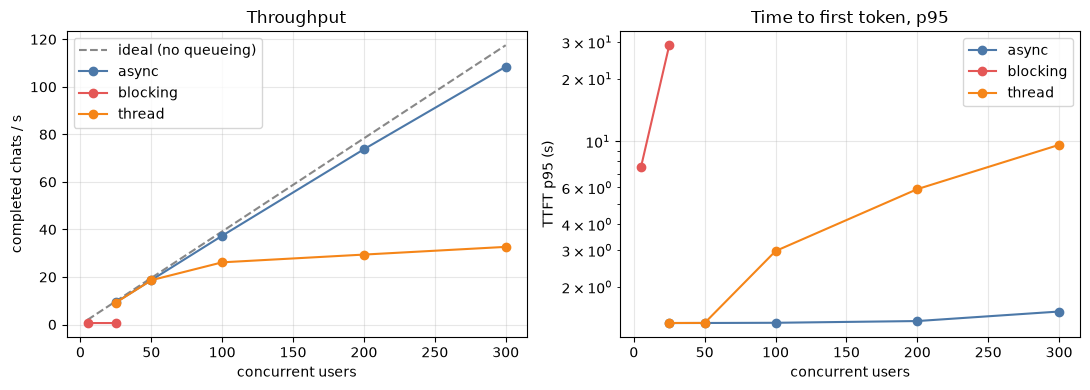

In [7]:
def ideal(users):  # closed-loop upper bound: each user = 1 chat per (latency + mean think time)
    return users / (LATENCY_S + 1.0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df = pd.DataFrame(ladder)
xs = sorted(df.users.unique())
axes[0].plot(xs, [ideal(u) for u in xs], color="#888", ls="--", label="ideal (no queueing)")
colors = {"blocking": "#E45756", "thread": "#F58518", "async": "#4C78A8"}
for mode, g in df.groupby("mode"):
    axes[0].plot(g.users, g.throughput_rps, "o-", color=colors[mode], label=mode)
    axes[1].plot(g.users, g.ttft_p95_ms / 1000, "o-", color=colors[mode], label=mode)
axes[0].set(xlabel="concurrent users", ylabel="completed chats / s", title="Throughput")
axes[1].set(xlabel="concurrent users", ylabel="TTFT p95 (s)", title="Time to first token, p95",
            yscale="log")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "21-throughput-latency.png", dpi=150)
plt.show()

## 4. Iterations: thread pool, connection pool, retries

In [8]:
fixes = [
    lt.run_experiment("thread", 300, 30, mock_cfg=MOCK, app_env={"CH21_THREAD_LIMIT": "400"},
                      tag="thread-u300-threads400"),
    lt.run_experiment("async", 100, 30, mock_cfg=MOCK, app_env={"CH21_MAX_CONNECTIONS": "20"},
                      tag="async-u100-pool20"),
    lt.run_experiment("async", 100, 30, mock_cfg=MOCK, tag="async-u100-pool-default"),
    lt.run_experiment("async", 300, 30, mock_cfg=MOCK, workers=4, tag="async-u300-workers4"),
]
show(fixes)

                    tag  users  throughput_rps  chats_ok  chats_failed  ttft_p50_ms  ttft_p95_ms  chat_p95_ms  healthz_p95_ms  healthz_max_ms  mock_max_in_flight
 thread-u300-threads400    300          103.03      2733             0         1400         1459         2174              78              91                 228
      async-u100-pool20    100           12.21       360             0         6951         7458         7795               2               6                  20
async-u100-pool-default    100           37.37       990             0         1338         1344         1687               5               7                  76
    async-u300-workers4    300          111.62      2955             0         1338         1341         1689               3              29                 230


In [9]:
mock_429 = {**MOCK, "rate_429": 0.10, "retry_after_s": 1}
retries = [
    lt.run_experiment("async", 100, 30, mock_cfg=mock_429, app_env={"CH21_MAX_RETRIES": "0"},
                      tag="async-u100-429-retries0"),
    lt.run_experiment("async", 100, 30, mock_cfg=mock_429, app_env={"CH21_MAX_RETRIES": "2"},
                      tag="async-u100-429-retries2"),
]
show(retries, cols=("tag", "throughput_rps", "chats_ok", "chats_failed", "error_rate",
                    "ttft_p50_ms", "ttft_p95_ms", "chat_p95_ms", "mock_requests"))

                    tag  throughput_rps  chats_ok  chats_failed  error_rate  ttft_p50_ms  ttft_p95_ms  chat_p95_ms  mock_requests
async-u100-429-retries0           34.10       903           176      0.1631         1338         1342         1685           1051
async-u100-429-retries2           35.09       956             1      0.0010         1338         2342         2684           1162


### Retry storms: 300 requests against a provider that allows 50 requests/s

The mock's own token bucket (50/s, burst 50) plays the provider's rate limit and answers 429 with
`Retry-After: 1`. Each strategy must get all 300 requests through.

In [10]:
HERD = {"ttft_ms": 200, "tokens_per_s": 500, "output_tokens": 10, "rps_limit": 50, "burst": 50,
        "retry_after_s": 1}
MOCK_URL = f"http://127.0.0.1:{lt.MOCK_PORT}"

async def herd(strategy: str, n: int = 300, limiter_rate: float = 45) -> dict:
    lt.post_json(MOCK_URL + "/admin/reset", {})
    sdk_retries = 10 if strategy in ("sdk", "client bucket") else 0
    client = openai.AsyncOpenAI(base_url=MOCK_URL + "/v1", api_key="x", max_retries=sdk_retries,
                                timeout=60)
    pool = aredis.BlockingConnectionPool.from_url(REDIS_URL, max_connections=50, timeout=5)
    bucket = AsyncRedisTokenBucket(aredis.Redis(connection_pool=pool), limiter_rate, limiter_rate)
    key = f"provider:{uuid.uuid4().hex}"

    def call():
        return client.chat.completions.create(
            model="mock", max_tokens=10, messages=[{"role": "user", "content": "hi"}])

    async def one():
        if strategy == "sdk":
            return await call()
        if strategy == "client bucket":
            while True:
                ok, wait = await bucket.acquire(key)
                if ok:
                    return await call()
                await asyncio.sleep(wait + random.uniform(0, 0.05))
        delay = exponential_delay if strategy == "exponential" else full_jitter_delay
        return await retry_async(call, attempts=11, delay=delay)

    t0 = time.time()
    res = await asyncio.gather(*[one() for _ in range(n)], return_exceptions=True)
    makespan = time.time() - t0
    stats = lt._get(MOCK_URL + "/admin/stats?arrivals=true")
    await client.close()
    await pool.aclose()
    return {"strategy": strategy, "makespan_s": round(makespan, 2),
            "upstream_calls": stats["requests"], "429s": stats["status_429"],
            "failed": sum(isinstance(x, Exception) for x in res),
            "arrivals": [a - t0 for a in stats["arrivals"]]}

herd_results = []
with lt.server("mock_llm_server:app", lt.MOCK_PORT, lt.mock_env(**HERD), ready_path="/v1/models"):
    for s in ("sdk", "exponential", "full jitter", "client bucket"):
        herd_results.append(await herd(s))
        await asyncio.sleep(2)  # let the provider bucket refill
print(pd.DataFrame(herd_results).drop(columns="arrivals").to_string(index=False))

     strategy  makespan_s  upstream_calls  429s  failed
          sdk        5.86             985   685       0
  exponential       16.42            1042   742       0
  full jitter        9.77            1085   785       0
client bucket        6.00             300     0       0


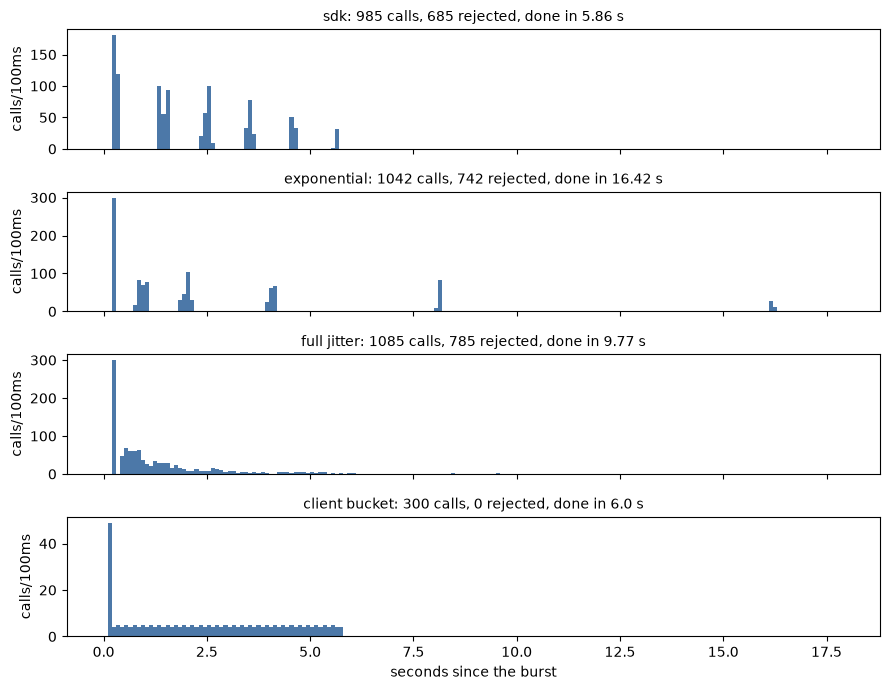

In [11]:
fig, axes = plt.subplots(len(herd_results), 1, figsize=(9, 7), sharex=True)
for ax, r in zip(axes, herd_results):
    ax.hist(r["arrivals"], bins=[i / 10 for i in range(0, 180)], color="#4C78A8")
    ax.set_ylabel("calls/100ms")
    ax.set_title(f"{r['strategy']}: {r['upstream_calls']} calls, {r['429s']} rejected, "
                 f"done in {r['makespan_s']} s", fontsize=10)
axes[-1].set_xlabel("seconds since the burst")
fig.tight_layout()
fig.savefig(IMAGES / "21-retry-storm.png", dpi=150)
plt.show()

## 5. A Redis token bucket shared by every replica

Four processes (think: four API replicas) each try to send as many requests as possible for 5 s
under a limit of 20 requests/s, burst 20. First with an in-process bucket each, then with one
bucket in Redis.

In [12]:
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context

from ch21_ratelimit import hammer

limiter_rows = []
for kind in ("in-process", "redis"):
    key = f"demo:{uuid.uuid4().hex}"
    with ProcessPoolExecutor(4, mp_context=get_context("spawn")) as pool:
        per_proc = list(pool.map(hammer, [kind] * 4, [key] * 4, [REDIS_URL] * 4))
    limiter_rows.append({"bucket": kind, "allowed per process": per_proc,
                         "total allowed in 5 s": sum(per_proc),
                         "limit (20/s x 5 s + burst 20)": 120})
print(pd.DataFrame(limiter_rows).to_string(index=False))

rb = RedisTokenBucket(redis.Redis.from_url(REDIS_URL), rate=1000, capacity=1000)
lat = []
for _ in range(2000):
    t = time.perf_counter()
    rb.acquire("latency-probe")
    lat.append((time.perf_counter() - t) * 1000)
lat.sort()
print(f"\nRedis token-bucket call latency: p50 {lat[1000]:.3f} ms, p99 {lat[1980]:.3f} ms")

    bucket  allowed per process  total allowed in 5 s  limit (20/s x 5 s + burst 20)
in-process [119, 119, 119, 119]                   476                            120
     redis     [32, 25, 34, 28]                   119                            120

Redis token-bucket call latency: p50 0.065 ms, p99 0.088 ms


In [13]:
per_user = lt.run_experiment("async", 50, 30, mock_cfg=MOCK, think=(0.1, 0.3),
                             app_env={"CH21_USER_RPS": "0.2", "CH21_USER_BURST": "3"},
                             tag="async-u50-user-limit")
show([per_user], cols=("tag", "throughput_rps", "chats_ok", "chats_failed", "error_rate",
                       "mock_requests", "ttft_p95_ms"))
print(per_user["errors"])

                 tag  throughput_rps  chats_ok  chats_failed  error_rate  mock_requests  ttft_p95_ms
async-u50-user-limit           13.15       341          3229      0.9045            399         1341
{'HTTP 429': 3229}


## 6. Multi-provider failover under load

Two mock providers. Ten seconds into a 30 s run, the primary starts answering every request with
HTTP 500; ten seconds later it recovers. Once with one provider, once with failover.

In [14]:
def outage_run(tag: str, two_providers: bool, users: int = 50, duration: int = 30):
    primary = f"http://127.0.0.1:{lt.MOCK_PORT}"
    urls = primary + "/v1" + (",http://127.0.0.1:8221/v1" if two_providers else "")
    timers = [threading.Timer(10, lt.post_json, (primary + "/admin/config", {"rate_500": 1.0})),
              threading.Timer(20, lt.post_json, (primary + "/admin/config", {"rate_500": 0.0}))]
    with lt.server("mock_llm_server:app", lt.MOCK_PORT, lt.mock_env(**MOCK),
                   ready_path="/v1/models", name="mock-primary"), \
         lt.server("mock_llm_server:app", 8221, lt.mock_env(**MOCK), ready_path="/v1/models",
                   name="mock-secondary"), \
         lt.server("ch21_chat_api:app", lt.API_PORT, {"CH21_MODE": "async",
                                                      "CH21_LLM_BASE_URLS": urls},
                   name=f"api-{tag}") as api:
        t0 = time.time()
        for t in timers:
            t.start()
        events = lt.run_locust(api, users, duration, tag)
        for t in timers:
            t.cancel()
    rows = [r for r in lt.load_events(events) if r["name"] == "chat"]
    for r in rows:
        r["t"] = r["ts"] - t0
    return rows

outages = {"single provider": outage_run("outage-single", False),
           "failover": outage_run("outage-failover", True)}
for name, rows in outages.items():
    during = [r for r in rows if 10 <= r["t"] < 20]
    ok = [r["ms"] for r in during if r["ok"]]
    served = Counter(r["provider"].split(":")[0] for r in during if r["ok"])
    print(f"{name:16s} during outage: {len(ok)} ok, {len(during) - len(ok)} failed, "
          f"served by {dict(served)}, p95 {lt.pct(ok, 95) or 0:.0f} ms | whole run: "
          f"{sum(r['ok'] for r in rows)} ok / {len(rows)}")

single provider  during outage: 30 ok, 426 failed, served by {'p0': 30}, p95 1685 ms | whole run: 271 ok / 937
failover         during outage: 178 ok, 0 failed, served by {'p0': 36, 'p1': 142}, p95 3043 ms | whole run: 527 ok / 527


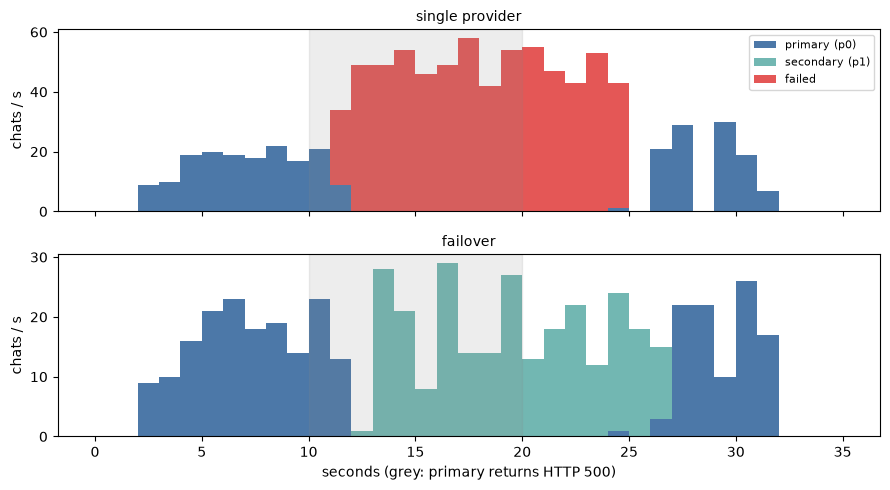

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax, (name, rows) in zip(axes, outages.items()):
    bins = [i for i in range(0, 36)]
    series = {"primary (p0)": [r["t"] for r in rows if r["ok"] and r["provider"].startswith("p0")],
              "secondary (p1)": [r["t"] for r in rows if r["ok"] and r["provider"].startswith("p1")],
              "failed": [r["t"] for r in rows if not r["ok"]]}
    ax.hist(list(series.values()), bins=bins, stacked=True, label=list(series),
            color=["#4C78A8", "#72B7B2", "#E45756"])
    ax.axvspan(10, 20, color="#888", alpha=0.15)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("chats / s")
axes[0].legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("seconds (grey: primary returns HTTP 500)")
fig.tight_layout()
fig.savefig(IMAGES / "21-failover.png", dpi=150)
plt.show()

The same `stream_with_failover` with real providers: a primary that is down (the mock with
`rate_500=1.0`), OpenRouter, and (only with `CH21_RUN_LOCAL=1`) a local Ollama model as the last
resort. To simulate an OpenRouter outage we point that provider at a closed port.

In [16]:
RUN_LOCAL = os.environ.get("CH21_RUN_LOCAL") == "1"  # needs Ollama with a free GPU
openrouter = openai.AsyncOpenAI(base_url=settings.llm_base_url, api_key=settings.llm_api_key,
                                max_retries=0, timeout=30)
dead_openrouter = openai.AsyncOpenAI(base_url="http://127.0.0.1:9/v1", api_key="x",
                                     max_retries=0, timeout=5)
local = []
if RUN_LOCAL:
    tags = {m["name"] for m in lt._get("http://localhost:11434/api/tags")["models"]}
    local_model = next(m for m in ("qwen3:1.7b", "qwen3:8b", "gemma3:4b") if m in tags)
    ollama = openai.AsyncOpenAI(base_url="http://localhost:11434/v1", api_key="ollama",
                                max_retries=0, timeout=60)
    local_opts = {"reasoning_effort": "none"} if local_model.startswith("qwen3") else {}
    local = [Provider(f"ollama {local_model}", ollama, local_model, local_opts)]
msgs = [{"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": "How long do I have to return an item? One sentence."}]

async def chain(openrouter_client):
    mock = openai.AsyncOpenAI(base_url=MOCK_URL + "/v1", api_key="x", max_retries=0)
    providers = [Provider("mock (down)", mock, "mock"),
                 Provider("openrouter", openrouter_client, settings.llm_model,
                          {"reasoning_effort": "none"}), *local]
    t = time.perf_counter()
    name, text, meta = await complete_with_failover(providers, msgs, max_tokens=120)
    return name, round(time.perf_counter() - t, 2), meta.get("skipped"), text, meta.get("usage", {})

print("providers:", ["mock (down)", "openrouter", *(p.name for p in local)])
with lt.server("mock_llm_server:app", lt.MOCK_PORT, lt.mock_env(**{**MOCK, "rate_500": 1.0}),
               ready_path="/v1/models", name="mock-down"):
    for label, orc in (("OpenRouter up", openrouter), ("OpenRouter down", dead_openrouter)):
        try:
            name, secs, skipped, text, usage = await chain(orc)
        except AllProvidersFailed as exc:
            print(f"[{label}] {type(exc).__name__}: {exc.errors}\n")
            continue
        spend[f"failover {label}"] = usage.get("cost", 0.0) or 0.0
        print(f"[{label}] served by {name} in {secs}s; skipped: {skipped}\n  -> {text.strip()}\n")

providers: ['mock (down)', 'openrouter', 'ollama qwen3:1.7b']


[OpenRouter up] served by openrouter in 1.47s; skipped: {'mock (down)': 'InternalServerError: 500'}
  -> You can return most items within 30 days of delivery, provided they’re unused and in their original packaging.



[OpenRouter down] served by ollama qwen3:1.7b in 1.98s; skipped: {'mock (down)': 'InternalServerError: 500', 'openrouter': 'APIConnectionError:'}
  -> You can return an item within 30 days of delivery.



## 7. Async work: a Postgres job queue with `FOR UPDATE SKIP LOCKED`

Jobs are "summarize this support ticket" calls to the mock (TTFT 200 ms, 20 tokens at 200 tok/s,
about 0.3 s each). Three ways to run 8 workers over 100 jobs, then the lease-based worker at
1–32 workers over 300 jobs. A sampler counts connections sitting `idle in transaction` meanwhile.

In [17]:
QCFG = {"ttft_ms": 200, "tokens_per_s": 200, "output_tokens": 20}

def worker_conn():
    c = connect()
    c.execute("SET application_name = 'ch21-worker'")
    return c

def run_queue(n_workers: int, n_jobs: int, variant: str) -> dict:
    conn = connect()
    q.setup(conn, reset=True)
    q.enqueue(conn, "summarize_ticket", [{"ticket": i} for i in range(n_jobs)])
    llm = openai.OpenAI(base_url=MOCK_URL + "/v1", api_key="x", max_retries=2)

    def handler(job):
        r = llm.chat.completions.create(model="mock", max_tokens=20, messages=[
            {"role": "user", "content": f"Summarize ticket {job.payload['ticket']}"}])
        return {"summary": r.choices[0].message.content}

    run = {"lease + SKIP LOCKED": lambda i: q.run_worker(worker_conn, f"w{i}", handler),
           "transaction + SKIP LOCKED": lambda i: q.run_worker_in_transaction(
               worker_conn, f"w{i}", handler, skip_locked=True),
           "transaction + FOR UPDATE": lambda i: q.run_worker_in_transaction(
               worker_conn, f"w{i}", handler, skip_locked=False)}[variant]
    idle_tx, stop = [], threading.Event()

    def sample():
        c = connect()
        while not stop.is_set():
            idle_tx.append(c.execute(
                "SELECT count(*) FROM pg_stat_activity WHERE application_name = 'ch21-worker' "
                "AND state = 'idle in transaction'").fetchone()[0])
            time.sleep(0.05)
        c.close()

    sampler = threading.Thread(target=sample)
    sampler.start()
    t = time.perf_counter()
    with ThreadPoolExecutor(n_workers) as ex:
        stats = list(ex.map(run, range(n_workers)))
    elapsed = time.perf_counter() - t
    stop.set()
    sampler.join()
    dup = conn.execute("SELECT count(*) FROM (SELECT job_id FROM ch21.job_runs GROUP BY 1 "
                       "HAVING count(*) > 1) d").fetchone()[0]
    done = conn.execute("SELECT count(*) FROM ch21.jobs WHERE status = 'done'").fetchone()[0]
    conn.close()
    claims = sum(s["claimed"] + s["empty_claims"] for s in stats)
    return {"variant": variant, "workers": n_workers, "jobs": n_jobs, "done": done,
            "jobs_run_twice": dup, "seconds": round(elapsed, 2),
            "jobs_per_s": round(n_jobs / elapsed, 1),
            "avg_claim_ms": round(sum(s["claim_ms"] for s in stats) / max(1, claims), 1),
            "max_idle_in_tx": max(idle_tx, default=0)}

with lt.server("mock_llm_server:app", lt.MOCK_PORT, lt.mock_env(**QCFG), ready_path="/v1/models"):
    variants = [run_queue(8, 100, v) for v in ("transaction + FOR UPDATE",
                                               "transaction + SKIP LOCKED",
                                               "lease + SKIP LOCKED")]
    scaling = [run_queue(n, 300, "lease + SKIP LOCKED") for n in (1, 4, 16, 32)]
print(pd.DataFrame(variants).to_string(index=False))
print()
print(pd.DataFrame(scaling).to_string(index=False))

                  variant  workers  jobs  done  jobs_run_twice  seconds  jobs_per_s  avg_claim_ms  max_idle_in_tx
 transaction + FOR UPDATE        8   100   100               0    29.90         3.3        1937.1               1
transaction + SKIP LOCKED        8   100   100               0     3.93        25.4           0.3               8
      lease + SKIP LOCKED        8   100   100               0     3.94        25.4           1.4               4

            variant  workers  jobs  done  jobs_run_twice  seconds  jobs_per_s  avg_claim_ms  max_idle_in_tx
lease + SKIP LOCKED        1   300   300               0    89.85         3.3           1.2               1
lease + SKIP LOCKED        4   300   300               0    22.50        13.3           1.5               1
lease + SKIP LOCKED       16   300   300               0     5.74        52.2           1.5               3
lease + SKIP LOCKED       32   300   300               0     3.07        97.6           2.0               3


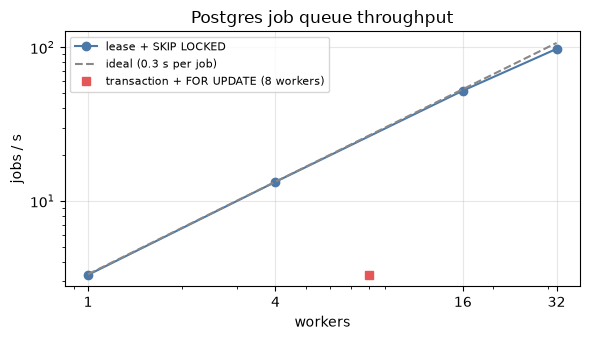

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sdf = pd.DataFrame(scaling)
ax.plot(sdf.workers, sdf.jobs_per_s, "o-", color="#4C78A8", label="lease + SKIP LOCKED")
ax.plot(sdf.workers, [w / 0.3 for w in sdf.workers], color="#888", ls="--",
        label="ideal (0.3 s per job)")
naive = variants[0]
ax.plot([naive["workers"]], [naive["jobs_per_s"]], "s", color="#E45756",
        label="transaction + FOR UPDATE (8 workers)")
ax.set(xlabel="workers", ylabel="jobs / s", xscale="log", yscale="log",
       title="Postgres job queue throughput")
ax.set_xticks(list(sdf.workers), labels=[str(x) for x in sdf.workers])
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "21-queue.png", dpi=150)
plt.show()

## 8. Results and sizing

In [19]:
# Capacity of one process = the most concurrent streams it held while TTFT p95 stayed within
# 10% of the model's own TTFT (the mock's configured value).
ok_runs = [r for r in ladder if r["mode"] == "async" and r["ttft_p95_ms"] <= 1.1 * MOCK["ttft_ms"]]
best = max(ok_runs, key=lambda r: r["mock_max_in_flight"])
per_server = best["mock_max_in_flight"]
need = p["peak_concurrency"] * burst
print(f"design concurrency {need:,.0f} streams; one async process held {per_server} streams "
      f"({best['tag']}: {best['throughput_rps']} chats/s, TTFT p95 {best['ttft_p95_ms']} ms)")
print(f"-> {servers_needed(need, per_server, headroom=0.7)} API process(es) at 70% of that, "
      f"plus one for redundancy")
summary = {"mock": MOCK, "latency_s": LATENCY_S, "plan": p, "burst": burst, "ladder": ladder,
           "fixes": fixes, "retries": retries,
           "herd": [{k: v for k, v in r.items() if k != "arrivals"} for r in herd_results],
           "limiter": limiter_rows, "per_user": per_user, "queue_variants": variants,
           "queue_scaling": scaling, "spend_usd": spend}
(lt.RESULTS / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("OpenRouter spend in this notebook:", {k: round(v, 6) for k, v in spend.items()},
      f"total {sum(spend.values()):.6f} USD")

design concurrency 99 streams; one async process held 157 streams (async-u200: 73.75 chats/s, TTFT p95 1369 ms)
-> 1 API process(es) at 70% of that, plus one for redundancy
OpenRouter spend in this notebook: {'calibration': 0.000272, 'failover OpenRouter up': 2.7e-05, 'failover OpenRouter down': 0.0} total 0.000298 USD


In [20]:
conn.close()
if started_redis:
    subprocess.run(["docker", "stop", "ch21-redis"], check=True, capture_output=True)
print("cleanup done; redis stopped:", started_redis)

cleanup done; redis stopped: True
